
# Uniform AR(p) experiments via zonotope intrinsic volumes

This notebook studies **ordinary AR(p) processes**, not the special delayed model
\(X_t=\rho X_{t-p}+\varepsilon_t\).

We use uniform innovations and the finite-history support zonotope of the sliding-window vector

\[
Y_t^{(k)}=(X_t,\ldots,X_{t+k-1}).
\]

The central question is:

> Do intrinsic volumes of these zonotopes show a recognizable signature of the AR order \(p\)?

The short answer from the experiments below is: **not as a universal kink at \(k=p\) or \(k=p+1\)**. For a generic AR(p), lower lags are already active, so the embedded zonotope is non-box-like already at small \(k\). Intrinsic volumes still react to the dependence structure, but they depend strongly on the coefficient values, not just on the formal order.


In [1]:

import math
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")



## Stable AR(p) coefficients

To avoid accidentally generating unstable AR processes, we parameterize coefficients by partial autocorrelations.

If every partial autocorrelation lies in \((-1,1)\), the resulting AR process is stationary. We use this in two ways:

1. a deterministic full AR(p) family, where every lag is active;
2. a random full AR(p) ensemble, where the last lag is kept away from zero so the process is genuinely order \(p\).


In [2]:

def pacf_to_ar_coefficients(partial_autocorrelations):
    """Convert partial autocorrelations to stationary AR coefficients."""
    partial_autocorrelations = np.asarray(partial_autocorrelations, dtype=float)
    if np.any(np.abs(partial_autocorrelations) >= 1):
        raise ValueError("All partial autocorrelations must be strictly between -1 and 1.")

    coefficients = np.array([], dtype=float)
    for kappa in partial_autocorrelations:
        previous = coefficients.copy()
        coefficients = np.empty(len(previous) + 1)
        if len(previous):
            coefficients[:-1] = previous - kappa * previous[::-1]
        coefficients[-1] = kappa
    return coefficients


def companion_matrix(phi):
    phi = np.asarray(phi, dtype=float)
    p = len(phi)
    matrix = np.zeros((p, p))
    matrix[0] = phi
    if p > 1:
        matrix[1:, :-1] = np.eye(p - 1)
    return matrix


def spectral_radius(phi):
    return float(np.max(np.abs(np.linalg.eigvals(companion_matrix(phi)))))


def deterministic_full_ar_coefficients(p, scale=0.55, decay=0.72):
    # All partial autocorrelations are nonzero, hence the generated AR(p) is full order.
    pacf = np.array([
        scale * (decay ** j) * ((-1) ** j)
        for j in range(p)
    ])
    return pacf_to_ar_coefficients(pacf)


def random_full_ar_coefficients(p, rng, pacf_bound=0.65, minimum_last_pacf=0.18):
    # Draw stationary AR(p) coefficients. Keep the last partial autocorrelation away from 0
    # so this is not numerically almost AR(p-1).
    pacf = rng.uniform(-pacf_bound, pacf_bound, size=p)
    if abs(pacf[-1]) < minimum_last_pacf:
        pacf[-1] = math.copysign(minimum_last_pacf, pacf[-1] if pacf[-1] != 0 else rng.choice([-1, 1]))
    return pacf_to_ar_coefficients(pacf)



## Zonotope generators and intrinsic volumes

For uniform innovations \(\varepsilon_t\in[-a,a]\), the finite-history support of \(Y_t^{(k)}\) is a zonotope.

If this zonotope is generated by the columns of \(G\), then

\[
V_j(Z)=\sum_{|I|=j}\sqrt{\det(G_I^\top G_I)}.
\]

We normalize by the intrinsic volume of the coordinate-wise marginal support box. This makes the plots easier to compare across orders and coefficient scales:

\[
R_j(k)=\frac{V_j(Z_{k,m})}{V_j(B_{k,m})}.
\]

A ratio near 1 means the support is close to axis-aligned box geometry. Smaller values indicate more oblique/shared innovation directions.


In [3]:

def ar_impulse_response(phi, maximum_lag):
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    psi = np.zeros(maximum_lag + 1)
    psi[0] = 1.0
    for lag in range(1, maximum_lag + 1):
        psi[lag] = sum(
            phi[j - 1] * psi[lag - j]
            for j in range(1, min(order, lag) + 1)
        )
    return psi


def ar_window_zonotope_generators(phi, embedding_dimension, history, half_width=1.0):
    k = embedding_dimension
    psi = ar_impulse_response(phi, history + k + 5)
    columns = []
    for innovation_time in range(-history, k):
        column = np.zeros(k)
        for coordinate in range(k):
            lag = coordinate - innovation_time
            if lag >= 0:
                column[coordinate] = 2 * half_width * psi[lag]
        if np.linalg.norm(column) > 1e-13:
            columns.append(column)
    return np.column_stack(columns)


def parallelotope_j_volume(generator_subset):
    gram = generator_subset.T @ generator_subset
    sign, log_determinant = np.linalg.slogdet(gram)
    if sign <= 0:
        return 0.0
    return float(np.exp(0.5 * log_determinant))


def exact_intrinsic_volume(generators, order):
    generators = np.asarray(generators, dtype=float)
    if order == 0:
        return 1.0
    if order == 1:
        return float(np.linalg.norm(generators, axis=0).sum())
    return float(sum(
        parallelotope_j_volume(generators[:, index_set])
        for index_set in combinations(range(generators.shape[1]), order)
    ))


def marginal_box_intrinsic_volume(generators, order):
    if order == 0:
        return 1.0
    side_lengths = np.sum(np.abs(generators), axis=1)
    return float(sum(
        np.prod(side_lengths[list(index_set)])
        for index_set in combinations(range(len(side_lengths)), order)
    ))


def intrinsic_volume_ratio(phi, embedding_dimension, intrinsic_order, history=70):
    G = ar_window_zonotope_generators(phi, embedding_dimension, history)
    value = exact_intrinsic_volume(G, intrinsic_order)
    box_value = marginal_box_intrinsic_volume(G, intrinsic_order)
    return value / box_value



## Experiment 1: one deterministic full AR(p) family

Here every AR order has nonzero coefficients at all lags \(1,\ldots,p\). This is a better sanity check for ordinary AR(p) behavior than the delayed model.


In [4]:

maximum_p = 8
maximum_k = 16
history = 70

coefficient_table = []
deterministic_rows = []

for p in range(1, maximum_p + 1):
    phi = deterministic_full_ar_coefficients(p)
    coefficient_table.append({
        "p": p,
        "coefficients": np.round(phi, 5),
        "spectral_radius": spectral_radius(phi),
    })
    for k in range(2, maximum_k + 1):
        deterministic_rows.append({
            "p": p,
            "k": k,
            "V2_ratio": intrinsic_volume_ratio(phi, k, 2, history),
            "V3_ratio": intrinsic_volume_ratio(phi, k, 3, history) if k >= 3 else np.nan,
        })

deterministic_results = pd.DataFrame(deterministic_rows)
pd.DataFrame(coefficient_table)


,p,coefficients,spectral_radius
0,1,[0.55],0.550000
1,2,"[0.7678, -0.396]",0.629285
2,3,"[0.88071, -0.61492, 0.28512]",0.674883
3,4,"[0.93924, -0.74115, 0.46592, -0.20529]",0.696968
4,5,"[0.96958, -0.81001, 0.57546, -0.34411, 0.14781]",0.707763
5,6,"[0.98531, -0.84663, 0.6367, -0.43031, 0.25099,...",0.713193
6,7,"[0.99347, -0.86587, 0.66968, -0.4791, 0.31586,...",0.716027
7,8,"[0.99769, -0.8759, 0.6871, -0.50553, 0.35281, ...",0.717568


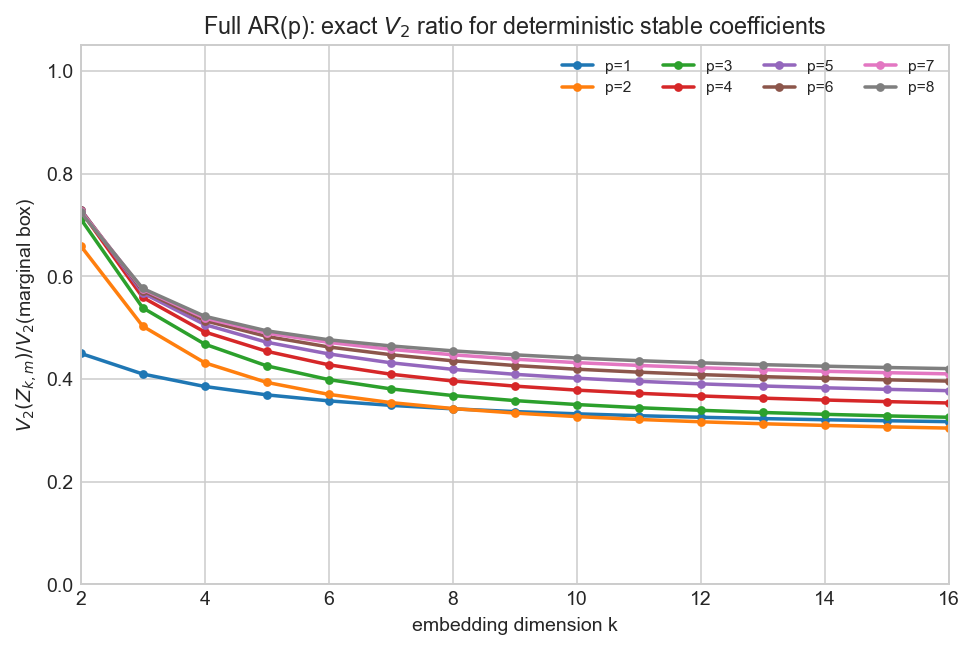

In [5]:

fig, ax = plt.subplots(figsize=(8, 5), dpi=140)
for p in range(1, maximum_p + 1):
    sub = deterministic_results[deterministic_results["p"] == p]
    ax.plot(sub["k"], sub["V2_ratio"], marker="o", linewidth=1.8, markersize=3.5, label=f"p={p}")

ax.set_title("Full AR(p): exact $V_2$ ratio for deterministic stable coefficients")
ax.set_xlabel("embedding dimension k")
ax.set_ylabel("$V_2(Z_{k,m}) / V_2$(marginal box)")
ax.set_xlim(2, maximum_k)
ax.set_ylim(0, 1.05)
ax.legend(ncol=4, fontsize=8)
plt.show()


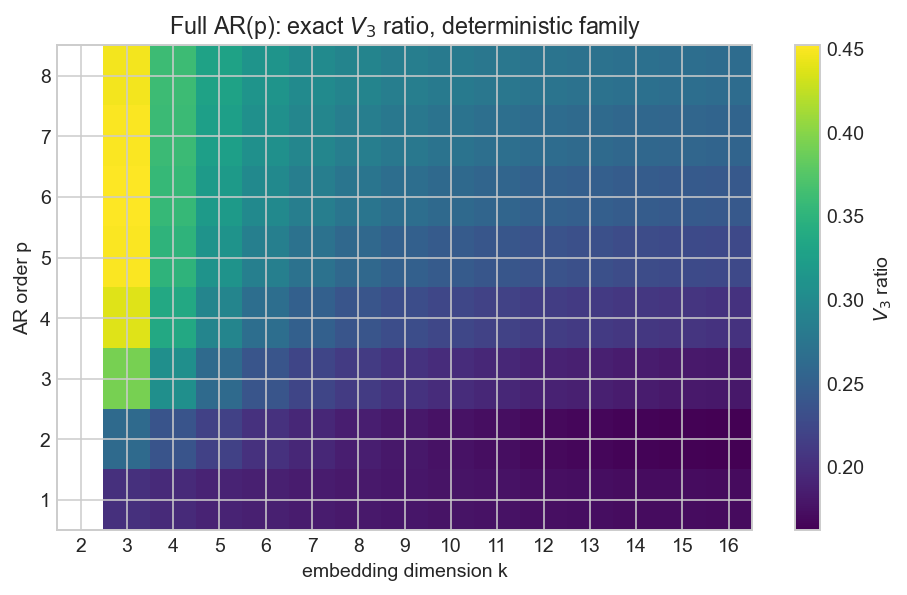

In [6]:

heatmap_values = deterministic_results.pivot(index="p", columns="k", values="V3_ratio")

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=140)
image = ax.imshow(
    heatmap_values.to_numpy(),
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=np.nanmin(heatmap_values.to_numpy()),
    vmax=np.nanmax(heatmap_values.to_numpy()),
    extent=[heatmap_values.columns.min() - 0.5, heatmap_values.columns.max() + 0.5, 0.5, maximum_p + 0.5],
)
ax.set_title("Full AR(p): exact $V_3$ ratio, deterministic family")
ax.set_xlabel("embedding dimension k")
ax.set_ylabel("AR order p")
ax.set_xticks(range(2, maximum_k + 1))
ax.set_yticks(range(1, maximum_p + 1))
fig.colorbar(image, ax=ax, label="$V_3$ ratio")
plt.show()



## Experiment 2: random stable full AR(p) ensemble

A single coefficient family can be misleading, so we also generate many stationary full AR(p) coefficient vectors. The plot shows the median and interquartile band of the normalized \(V_2\) ratio.

This is the more honest experiment if the question is about **AR order p in general** rather than a particular coefficient pattern.


In [7]:

rng = np.random.default_rng(2026)
replicates = 40
random_rows = []

for p in range(1, maximum_p + 1):
    for replicate in range(replicates):
        phi = random_full_ar_coefficients(p, rng)
        for k in range(2, maximum_k + 1):
            random_rows.append({
                "p": p,
                "replicate": replicate,
                "k": k,
                "V2_ratio": intrinsic_volume_ratio(phi, k, 2, history),
                "spectral_radius": spectral_radius(phi),
            })

random_results = pd.DataFrame(random_rows)
random_results.head()


,p,replicate,k,V2_ratio,spectral_radius
0,1,0,2,0.582615,0.417385
1,1,0,3,0.534032,0.417385
2,1,0,4,0.506344,0.417385
3,1,0,5,0.488621,0.417385
4,1,0,6,0.476376,0.417385


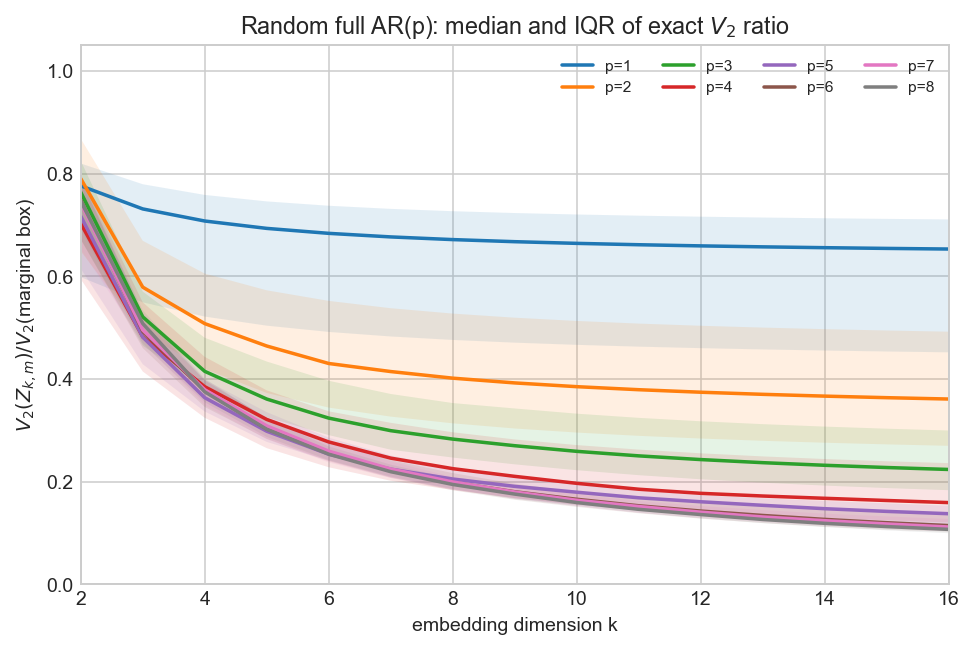

In [8]:

summary = (
    random_results
    .groupby(["p", "k"])["V2_ratio"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
    .reset_index()
    .rename(columns={0.25: "q25", 0.5: "median", 0.75: "q75"})
)

fig, ax = plt.subplots(figsize=(8, 5), dpi=140)
for p in range(1, maximum_p + 1):
    sub = summary[summary["p"] == p]
    ax.plot(sub["k"], sub["median"], linewidth=1.8, label=f"p={p}")
    ax.fill_between(sub["k"].to_numpy(), sub["q25"].to_numpy(), sub["q75"].to_numpy(), alpha=0.12)

ax.set_title("Random full AR(p): median and IQR of exact $V_2$ ratio")
ax.set_xlabel("embedding dimension k")
ax.set_ylabel("$V_2(Z_{k,m}) / V_2$(marginal box)")
ax.set_xlim(2, maximum_k)
ax.set_ylim(0, 1.05)
ax.legend(ncol=4, fontsize=8)
plt.show()


In [9]:

# A compact table at a few embedding dimensions.
selected_k = [2, 3, 5, 8, 12, 16]
(
    summary[summary["k"].isin(selected_k)]
    .pivot(index="p", columns="k", values="median")
    .round(3)
)


k,2,3,5,8,12,16
p,,,,,,
1,0.777,0.731,0.694,0.672,0.659,0.653
2,0.791,0.579,0.464,0.402,0.374,0.361
3,0.764,0.521,0.361,0.283,0.243,0.224
4,0.703,0.482,0.321,0.225,0.177,0.159
5,0.717,0.482,0.298,0.205,0.161,0.138
6,0.748,0.493,0.303,0.199,0.143,0.115
7,0.743,0.496,0.309,0.200,0.141,0.112
8,0.747,0.508,0.302,0.195,0.136,0.107



## Corrected takeaway

The delayed model gave a clean threshold at \(k=p+1\), but that threshold was a property of that sparse coefficient pattern, not of AR(p) processes in general.

For ordinary full AR(p) processes:

- the zonotope is usually already non-box-like at \(k=2\), because lag-1 dependence is active;
- there is no universal kink at \(k=p\) or \(k=p+1\);
- intrinsic-volume ratios still react strongly to dependence, but the coefficient values matter at least as much as the formal order;
- comparing ensembles over stable AR(p) coefficients is therefore more meaningful than expecting a single deterministic breakpoint.

So the corrected interpretation is:

\[
\text{intrinsic volumes diagnose dependence geometry, not AR order alone.}
\]

They may help distinguish model classes statistically, but the order \(p\) is not generally visible as a sharp geometric transition unless the coefficients have a special sparse lag structure.
